In [ ]:
import pandas as pd
import os
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

train = pd.read_csv("/content/train.csv")
test = pd.read_csv("/content/test.csv")
sample_submission = pd.read_csv("/content/sample_submission.csv")

print("Train:", train.shape)
print("Test:", test.shape)
print("sample_submission.csv:", sample_submission.shape)

Train: (8693, 14)
Test: (4277, 13)
sample_submission.csv: (4277, 2)


In [ ]:
train.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [ ]:
test.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name
0,0013_01,Earth,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,0.0,0.0,Nelly Carsoning
1,0018_01,Earth,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,2823.0,0.0,Lerome Peckers
2,0019_01,Europa,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,0.0,0.0,Sabih Unhearfus
3,0021_01,Europa,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,181.0,585.0,Meratz Caltilter
4,0023_01,Earth,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,0.0,0.0,Brence Harperez


In [ ]:
train.info()

train.isnull().sum()

train.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


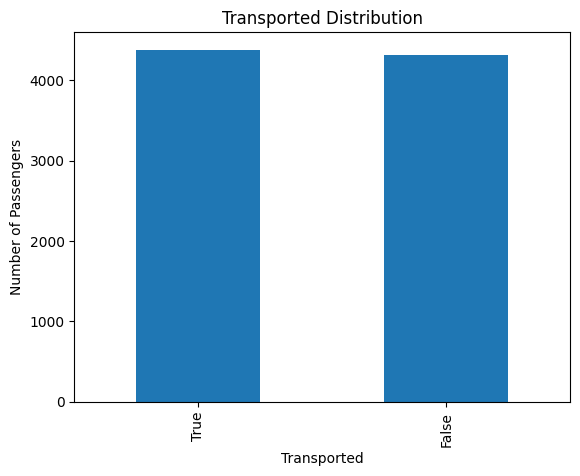

In [ ]:
import matplotlib.pyplot as plt

train["Transported"].value_counts().plot(kind="bar")

plt.title("Transported Distribution")
plt.xlabel("Transported")
plt.ylabel("Number of Passengers")
plt.show()

In [ ]:
train.groupby("CryoSleep")["Transported"].mean()


,Transported
CryoSleep,
False,0.328921
True,0.817583


In [ ]:
train.groupby("HomePlanet")["Transported"].mean()

,Transported
HomePlanet,
Earth,0.423946
Europa,0.658846
Mars,0.523024


In [ ]:
train.groupby("Destination")["Transported"].mean()

,Transported
Destination,
55 Cancri e,0.610000
PSO J318.5-22,0.503769
TRAPPIST-1e,0.471175


In [ ]:
spending = [
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck"
]

train.groupby("Transported")[spending].mean()

,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
Transported,,,,,
False,389.266066,382.615930,167.566217,564.382666,543.629822
True,63.098021,532.691984,179.829972,61.675531,69.148131


In [ ]:
train.groupby("Transported")["Age"].mean()

,Age
Transported,
False,29.922858
True,27.748834


In [ ]:
train.groupby("VIP")["Transported"].mean()

,Transported
VIP,
False,0.506332
True,0.381910


In [ ]:
spending = [
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck"
]

train["TotalSpend"] = train[spending].sum(axis=1)
test["TotalSpend"] = test[spending].sum(axis=1)

train[["TotalSpend"] + spending].head()

,TotalSpend,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
0,0.0,0.0,0.0,0.0,0.0,0.0
1,736.0,109.0,9.0,25.0,549.0,44.0
2,10383.0,43.0,3576.0,0.0,6715.0,49.0
3,5176.0,0.0,1283.0,371.0,3329.0,193.0
4,1091.0,303.0,70.0,151.0,565.0,2.0


In [ ]:
train.groupby("Transported")["TotalSpend"].mean()

,TotalSpend
Transported,
False,2004.149247
True,885.689127


In [ ]:
train[["Deck", "CabinNumber", "Side"]] = train["Cabin"].str.split("/", expand=True)
test[["Deck", "CabinNumber", "Side"]] = test["Cabin"].str.split("/", expand=True)

In [ ]:
train[["Cabin", "Deck", "CabinNumber", "Side"]].head(10)

,Cabin,Deck,CabinNumber,Side
0,B/0/P,B,0,P
1,F/0/S,F,0,S
2,A/0/S,A,0,S
3,A/0/S,A,0,S
4,F/1/S,F,1,S
5,F/0/P,F,0,P
6,F/2/S,F,2,S
7,G/0/S,G,0,S
8,F/3/S,F,3,S
9,B/1/P,B,1,P


In [ ]:
train.groupby("Deck")["Transported"].mean()

,Transported
Deck,
A,0.496094
B,0.734275
C,0.680054
D,0.433054
E,0.357306
F,0.439871
G,0.516217
T,0.200000


In [ ]:
train.groupby("Side")["Transported"].mean()

,Transported
Side,
P,0.451260
S,0.555037


In [ ]:
train.isnull().sum()

,0
PassengerId,0
HomePlanet,201
CryoSleep,217
Cabin,199
Destination,182
Age,179
VIP,203
RoomService,181
FoodCourt,183
ShoppingMall,208


In [ ]:
test.isnull().sum()

,0
PassengerId,0
HomePlanet,87
CryoSleep,93
Cabin,100
Destination,92
Age,91
VIP,93
RoomService,82
FoodCourt,106
ShoppingMall,98


In [ ]:
features = [
    "HomePlanet",
    "CryoSleep",
    "Destination",
    "Age",
    "VIP",
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck",
    "TotalSpend",
    "Deck",
    "CabinNumber",
    "Side"
]

X = train[features]
y = train["Transported"]

X_test = test[features]

print("X:", X.shape)
print("y:", y.shape)
print("X_test:", X_test.shape)

X: (8693, 14)
y: (8693,)
X_test: (4277, 14)


In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

Training: (6954, 14)
Validation: (1739, 14)


In [ ]:
numeric_features = [
    "Age",
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck",
    "TotalSpend",
    "CabinNumber"
]

categorical_features = [
    "HomePlanet",
    "CryoSleep",
    "Destination",
    "VIP",
    "Deck",
    "Side"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [ ]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Age', 'RoomService',
                                                   'FoodCourt', 'ShoppingMall',
                                                   'Spa', 'VRDeck',
                                                   'TotalSpend',
                                                   'CabinNumber']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['HomePlanet', 'CryoSleep',
                                                   'Destination', 'VIP', 'Deck',
                                                   'Side'])])),
                ('classifier',
                 RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                        random_state=42))])

In [ ]:
y_pred = model.predict(X_val)

accuracy = accuracy_score(y_val, y_pred)

print(f"Validation Accuracy: {accuracy:.4f}")

Validation Accuracy: 0.8108


In [ ]:
print(confusion_matrix(y_val, y_pred))
print()
print(classification_report(y_val, y_pred))

[[733 130]
 [199 677]]

              precision    recall  f1-score   support

       False       0.79      0.85      0.82       863
        True       0.84      0.77      0.80       876

    accuracy                           0.81      1739
   macro avg       0.81      0.81      0.81      1739
weighted avg       0.81      0.81      0.81      1739



In [ ]:
gradient_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        random_state=42
    ))
])

In [ ]:
gradient_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Age', 'RoomService',
                                                   'FoodCourt', 'ShoppingMall',
                                                   'Spa', 'VRDeck',
                                                   'TotalSpend',
                                                   'CabinNumber']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['HomePlanet', 'CryoSleep',
                                                   'Destination', 'VIP', 'Deck',
                                                   'Side'])])),
                ('classifier',
                 HistGradientBoostingClassifier(learning_rate=0.05,
                                                max_iter=300,
                                                random_state=42))])

In [ ]:
gradient_pred = gradient_model.predict(X_val)

gradient_accuracy = accuracy_score(y_val, gradient_pred)

print(f"Gradient Boosting Accuracy: {gradient_accuracy:.4f}")

Gradient Boosting Accuracy: 0.8171


In [ ]:
train["GroupId"] = train["PassengerId"].str.split("_").str[0].astype(int)
test["GroupId"] = test["PassengerId"].str.split("_").str[0].astype(int)

In [ ]:
group_sizes = train["GroupId"].value_counts()

train["GroupSize"] = train["GroupId"].map(group_sizes)
test["GroupSize"] = test["GroupId"].map(
    train["GroupId"].value_counts()
).fillna(1)

In [ ]:
train[["PassengerId", "GroupId", "GroupSize"]].head(10)

,PassengerId,GroupId,GroupSize
0,0001_01,1,1
1,0002_01,2,1
2,0003_01,3,2
3,0003_02,3,2
4,0004_01,4,1
5,0005_01,5,1
6,0006_01,6,2
7,0006_02,6,2
8,0007_01,7,1
9,0008_01,8,3


In [ ]:
test["GroupSize"] = test["GroupId"].map(
    train["GroupId"].value_counts()
).fillna(1)

In [ ]:
all_passengers = pd.concat([
    train[["PassengerId", "GroupId"]],
    test[["PassengerId", "GroupId"]]
])

all_group_sizes = all_passengers["GroupId"].value_counts()

train["GroupSize"] = train["GroupId"].map(all_group_sizes)
test["GroupSize"] = test["GroupId"].map(all_group_sizes)

print(train["GroupSize"].value_counts().sort_index())

GroupSize
1    4805
2    1682
3    1020
4     412
5     265
6     174
7     231
8     104
Name: count, dtype: int64


In [ ]:
features = [
    "HomePlanet",
    "CryoSleep",
    "Destination",
    "Age",
    "VIP",
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck",
    "TotalSpend",
    "Deck",
    "CabinNumber",
    "Side",
    "GroupId",
    "GroupSize"
]

In [ ]:
numeric_features = [
    "Age",
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck",
    "TotalSpend",
    "CabinNumber",
    "GroupId",
    "GroupSize"
]

In [ ]:
X = train[features]
y = train["Transported"]
X_test = test[features]

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Rebuilding preprocessor with the NEW feature lists
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Gradient Boosting model
gradient_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        random_state=42
    ))
])

# Train
gradient_model.fit(X_train, y_train)

# Validate
gradient_pred = gradient_model.predict(X_val)

new_accuracy = accuracy_score(y_val, gradient_pred)

print(f"New Gradient Boosting Accuracy: {new_accuracy:.4f}")

New Gradient Boosting Accuracy: 0.8137


In [ ]:
features = [
    "HomePlanet",
    "CryoSleep",
    "Destination",
    "Age",
    "VIP",
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck",
    "TotalSpend",
    "Deck",
    "CabinNumber",
    "Side"
]

numeric_features = [
    "Age",
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck",
    "TotalSpend",
    "CabinNumber"
]

categorical_features = [
    "HomePlanet",
    "CryoSleep",
    "Destination",
    "VIP",
    "Deck",
    "Side"
]

X = train[features]
y = train["Transported"]
X_test = test[features]

In [ ]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        random_state=42
    ))
])

final_model.fit(X, y)

print("Final model trained successfully!")

Final model trained successfully!


In [ ]:
test_predictions = final_model.predict(X_test)

print(test_predictions[:20])

[ True False  True  True  True False  True  True  True  True False False
 False False False False False  True  True False]


In [ ]:
submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Transported": test_predictions
})

submission.to_csv("submission.csv", index=False)

print(submission.head())
print(f"\nSubmission shape: {submission.shape}")

  PassengerId  Transported
0     0013_01         True
1     0018_01        False
2     0019_01         True
3     0021_01         True
4     0023_01         True

Submission shape: (4277, 2)


In [ ]:
print(os.path.exists("submission.csv"))
print(os.path.getsize("submission.csv"), "bytes")
print(submission.shape)
print(submission.head())

True
57727 bytes
(4277, 2)
  PassengerId  Transported
0     0013_01         True
1     0018_01        False
2     0019_01         True
3     0021_01         True
4     0023_01         True


In [ ]:
from google.colab import files

files.download("submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>